# Exercise 2 - Convolutional Neural Network classifier (CIFAR-10)

**PUSL3123 AI and Machine Learning - Assessment 1**

**Aim:** build, train and evaluate a Convolutional Neural Network (CNN) with three trainable layers on CIFAR-10 using PyTorch, and compare it with the Exercise 1 MLP baseline.

**Contents**
1. Setup and configuration
2. Data preparation (standard partitions, validation split, class distribution)
3. Helper functions (training, evaluation, plotting)
4. Model: three-layer CNN
5. Training
6. Training and validation curves
7. Final evaluation (train / validation / test)
8. Comparison with Exercise 1 (MLP)
9. Visualising what the convolutions learn
10. Save results

**How to run:** `pip install -r requirements.txt`, then *Run All*. Set the environment variable `QUICK_RUN=1` for a 2-epoch smoke test. The dataset downloads automatically into `data/`. Run `Ex1_MLP.ipynb` first so that `results/ex1_mlp.json` is available for the comparison section.

**Source acknowledgement:** this code was developed with assistance from a generative AI tool (Claude, Anthropic), as declared in Appendix A of the report. The author checked and ran all code. Libraries: PyTorch and torchvision (Paszke et al., 2019); dataset: CIFAR-10 (Krizhevsky, 2009).

## 1. Setup and configuration

All four notebooks share the same configuration (seed, validation size, batch size, learning rate, epochs) so that results are directly comparable.

In [1]:
import os, json, time, random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

# ---------------------------------------------------------------------------
# Configuration -- identical in all four notebooks so that results are comparable
# ---------------------------------------------------------------------------
SEED          = 42        # default run seed: weight initialisation, augmentation and batch shuffling
SPLIT_SEED    = 42        # train/validation split: identical for every experiment and every run
SEEDS         = (42, 43, 44)   # run seeds for the multi-seed experiments (Exercises 3 and 4)
VAL_SIZE      = 5_000     # validation images held out from the 50,000 training images
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 2 if os.environ.get("QUICK_RUN") else 30   # set QUICK_RUN=1 for a 2-epoch smoke test
DATA_DIR      = "data"
RESULTS_DIR   = "results"
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ("aeroplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed=SEED):
    """Seed one run: weight initialisation plus dropout and augmentation randomness."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
if DEVICE.type == "cpu":
    print("CUDA is not available, so the CPU is used: training is much slower, and results may differ slightly from the GPU run.")
print(f"Epochs: {EPOCHS} | batch size: {BATCH_SIZE} | learning rate: {LEARNING_RATE} | seed: {SEED}")

PyTorch 2.5.1+cu121 | torchvision 0.20.1+cu121
Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Epochs: 30 | batch size: 128 | learning rate: 0.001 | seed: 42


## 2. Data preparation

* CIFAR-10 is loaded with `torchvision.datasets.CIFAR10` using the **standard partitions**: 50,000 training images and 10,000 test images.
* The test partition is kept completely separate: it is **not** used for training, hyper-parameter tuning or model selection.
* A **validation set of 5,000 images is held out from the 50,000 training images** with a fixed seed (`SPLIT_SEED`), leaving 45,000 images for training. The same split is used in every experiment.
* Images are decoded once into a single `uint8` tensor that lives on `DEVICE` for the rest of the notebook. Each minibatch is normalised on the fly (see `GPULoader` below) with the per-channel mean and standard deviation of the full 50,000-image training partition, computed before the 5,000-image validation split is held out; including those images has a negligible effect, and the test set is not used, which avoids the per-sample CPU transforms and `DataLoader` worker overhead that otherwise dominate training time. No data augmentation is used in this exercise.

In [2]:
# Per-channel mean / std of the full 50,000-image CIFAR-10 training partition (computed before the
# validation split is held out; the effect is negligible and the test set is not used)
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T  = torch.tensor(STD,  device=DEVICE).view(1, 3, 1, 1)

class GPULoader:
    """Minibatch iterator over images held entirely on DEVICE as a single uint8 tensor.

    Keeping a whole partition resident on DEVICE and normalising per batch -- instead of per-sample
    disk reads and CPU transforms behind a `DataLoader` -- removes the CPU bottleneck in data loading.
    Shuffling uses a seeded CPU generator so that the epoch order is reproducible; `augment`, if given,
    is applied to the already-normalised batch on the GPU (used from Exercise 3 onwards).
    """
    def __init__(self, images, targets, batch_size, shuffle, seed=SEED, augment=None):
        """Store the partition tensors and create the seeded shuffling generator."""
        self.images, self.targets = images, targets   # uint8 (N,3,32,32) / int64 (N,), both on DEVICE
        self.batch_size, self.shuffle, self.augment = batch_size, shuffle, augment
        self.generator = torch.Generator().manual_seed(seed) if shuffle else None

    def __iter__(self):
        """Yield normalised (and optionally augmented) minibatches, reshuffled each epoch if `shuffle`."""
        n = self.images.size(0)
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        order = order.to(self.images.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            x = (self.images[idx].float() / 255 - MEAN_T) / STD_T
            if self.augment is not None:
                x = self.augment(x)
            yield x, self.targets[idx]

    def __len__(self):
        """Number of minibatches per epoch (the last one may be smaller)."""
        return (self.images.size(0) + self.batch_size - 1) // self.batch_size


_partitions = {}   # decoded tensors, cached so that repeated build_data calls never reload from disk

def load_partitions():
    """Decode CIFAR-10 into DEVICE memory once per kernel and apply the fixed train/validation split.
    Standard partitions (50,000 train / 10,000 test); VAL_SIZE images are held out from the training
    images using SPLIT_SEED, so the split is identical for every experiment and every run seed."""
    if not _partitions:
        try:
            train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True)
            test_raw  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
        except (OSError, RuntimeError) as error:   # no connection, interrupted download or corrupted files
            raise RuntimeError(
                f"Could not download or load CIFAR-10 into '{DATA_DIR}/'. Check the internet connection and "
                f"re-run, or download the Python version from https://www.cs.toronto.edu/~kriz/cifar.html and "
                f"place its extracted 'cifar-10-batches-py' folder inside '{DATA_DIR}/'.") from error

        def as_device_tensors(ds):
            """Convert a torchvision CIFAR-10 dataset to uint8 image and int64 label tensors on DEVICE."""
            images = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)  # (N,3,32,32) uint8
            targets = torch.tensor(ds.targets, dtype=torch.long, device=DEVICE)
            return images, targets

        train_images, train_targets = as_device_tensors(train_raw)
        test_images,  test_targets  = as_device_tensors(test_raw)

        perm = torch.randperm(len(train_raw), generator=torch.Generator().manual_seed(SPLIT_SEED))
        val_idx, train_idx = perm[:VAL_SIZE].to(DEVICE), perm[VAL_SIZE:].to(DEVICE)
        # Sanity checks: standard partition sizes and no image in both the training and validation sets
        assert (len(train_idx), len(val_idx), len(test_raw)) == (45_000, 5_000, 10_000), "unexpected partition sizes"
        assert not set(train_idx.tolist()) & set(val_idx.tolist()), "training and validation images overlap"
        _partitions.update(train=(train_images[train_idx], train_targets[train_idx]),
                           val=(train_images[val_idx], train_targets[val_idx]),
                           test=(test_images, test_targets))
    return _partitions


def build_data(augment=None, seed=SEED):
    """Loaders for the fixed partitions. `seed` only controls the shuffling of the training batches (the
    split always uses SPLIT_SEED). `augment` is an optional GPU-side callable applied only to the training
    batches (Exercise 3 onwards). The test set is never used for training or model selection."""
    partitions = load_partitions()

    def loader(name, shuffle=False, augment=None):
        """GPULoader over one partition; only the training loader is shuffled and augmented."""
        images, targets = partitions[name]
        return GPULoader(images, targets, BATCH_SIZE, shuffle=shuffle, seed=seed, augment=augment)

    return {
        "train":       loader("train", shuffle=True, augment=augment),  # used for training
        "train_clean": loader("train"),                                 # same images, no augmentation
        "val":         loader("val"),                                   # validation (model selection)
        "test":        loader("test"),                                  # final reporting only
    }

loaders = build_data()
print("Images per partition:", {k: v.images.shape[0] for k, v in loaders.items()})

Files already downloaded and verified


Files already downloaded and verified


Images per partition: {'train': 45000, 'train_clean': 45000, 'val': 5000, 'test': 10000}


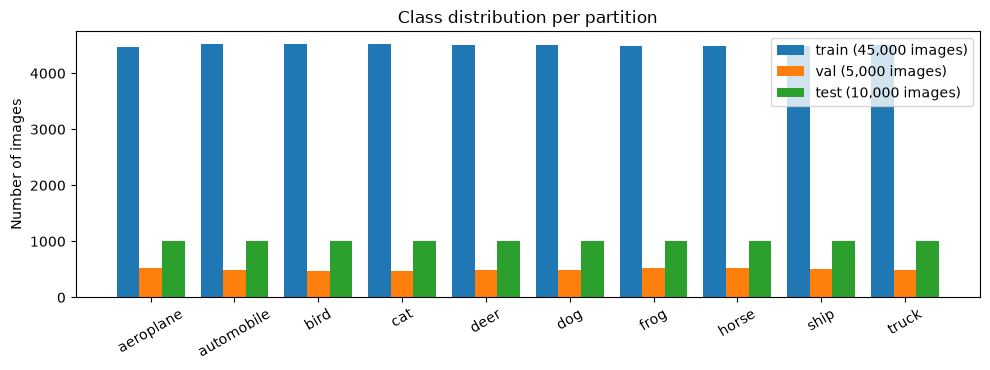

Files already downloaded and verified


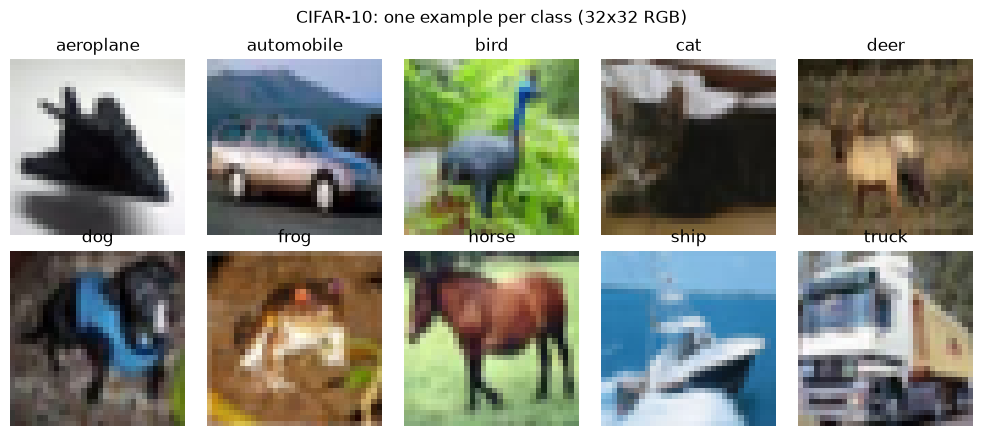

In [3]:
def class_counts(loader):
    """Number of images per class held by a GPULoader partition."""
    return np.bincount(loader.targets.cpu().numpy(), minlength=len(CLASSES))

counts = {name: class_counts(loaders[name]) for name in ("train", "val", "test")}

x, w = np.arange(len(CLASSES)), 0.27
plt.figure(figsize=(10, 3.8))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + (i - 1) * w, c, w, label=f"{name} ({c.sum():,} images)")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Number of images")
plt.title("Class distribution per partition")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=200)
plt.show()

# One example image per class
raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_targets = np.array(raw.targets)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(raw[int(np.where(raw_targets == c)[0][0])][0])
    ax.set_title(CLASSES[c])
    ax.axis("off")
fig.suptitle("CIFAR-10: one example per class (32x32 RGB)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cifar10_samples.png"), dpi=200)
plt.show()

## 3. Helper functions

* `fit` trains with **Adam** and **cross-entropy loss**, records loss and accuracy per epoch, and restores the weights of the epoch with the best **validation** accuracy.
* `evaluate` / `final_evaluation` compute loss and accuracy; the test set is only used in `final_evaluation`, after training has finished.
* Plotting and saving utilities produce the figures and JSON results used in the report.

In [4]:
def count_parameters(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    """Mean cross-entropy loss and accuracy of `model` on `loader` (eval mode: no dropout)."""
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0, verbose=True):
    """Train with Adam + cross-entropy. After every epoch the model is scored on the validation set; the
    weights of the epoch with the highest validation accuracy are restored at the end (model selection
    uses validation data only -- never the test set). Running loss/accuracy are accumulated as GPU
    tensors and only moved to the CPU once per epoch (`.item()`), instead of after every batch, since a
    host-device sync on every step would otherwise stall the GPU pipeline."""
    criterion = nn.CrossEntropyLoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = torch.zeros((), device=DEVICE)
        run_correct = torch.zeros((), device=DEVICE)
        seen = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimiser.step()
            run_loss += loss.detach() * y.size(0)
            run_correct += (out.argmax(1) == y).sum()
            seen += y.size(0)

        history["train_loss"].append((run_loss / seen).item())
        history["train_acc"].append((run_correct / seen).item())
        val_loss, val_acc = evaluate(model, val_loader)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f"Epoch {epoch:02d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"acc {history['train_acc'][-1]:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    return history, best_epoch, time.time() - start

def final_evaluation(model, loaders):
    """Loss / accuracy on the clean training images, the validation set and the test set."""
    result = {}
    for key, loader_name in (("train", "train_clean"), ("val", "val"), ("test", "test")):
        loss, acc = evaluate(model, loaders[loader_name])
        result[f"{key}_loss"], result[f"{key}_acc"] = loss, acc
    return result

def print_final(final):
    """Print the loss and accuracy of each partition and the train - test gap."""
    print(f"{'Partition':<12}{'Loss':>8}{'Accuracy':>11}")
    for part in ("train", "val", "test"):
        print(f"{part:<12}{final[part + '_loss']:>8.4f}{final[part + '_acc'] * 100:>10.2f}%")
    gap = (final["train_acc"] - final["test_acc"]) * 100
    print(f"Generalisation gap (train - test accuracy): {gap:.2f} percentage points")

def plot_history(history, best_epoch, title, filename):
    """Training vs validation loss (left) and accuracy (right)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    for ax in axes:
        ax.axvline(best_epoch, ls="--", c="grey", label=f"Selected epoch ({best_epoch})")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()

@torch.no_grad()
def predict(model, loader):
    """Predicted and true class labels for every image in `loader` (eval mode)."""
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(DEVICE)).argmax(1).cpu())
        labels.append(y.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def plot_confusion_matrix(model, loader, title, filename):
    """Confusion matrix (rows = true class, columns = predicted class). Returns the count matrix."""
    preds, labels = predict(model, loader)
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(cm, (labels, preds), 1)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xlabel="Predicted class",
           ylabel="True class", title=title)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()
    return cm

def save_results(name, payload):
    """Write results to results/<name>.json (used for the tables and graphs in the report)."""
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)
    print("Saved", path)

## 4. Model: three-layer convolutional network

The CNN keeps each image in its 3 x 32 x 32 spatial form instead of flattening it, and passes it through three trainable layers: two convolutional blocks (each a 3x3 convolution, ReLU and 2x2 max-pooling) followed by one fully connected classifier.

| Layer | Operation | Output shape | Activation |
|---|---|---|---|
| Conv 1 | Conv2d(3 -> 32, kernel 3x3, padding 1) + MaxPool2d(2) | 32 x 16 x 16 | ReLU |
| Conv 2 | Conv2d(32 -> 64, kernel 3x3, padding 1) + MaxPool2d(2) | 64 x 8 x 8 | ReLU |
| Linear 3 | Linear(4096 -> 10) | 10 | none (logits) |

**Design choices**
* **Convolutions** exploit the 2D structure of the image: each filter has a small local receptive field and the same weights are shared across every spatial position, unlike the MLP's fully connected layers, which treat every pixel as an independent input.
* **Max-pooling** halves the spatial resolution after each convolutional block, giving some robustness to small translations and reducing the amount of computation seen by later layers.
* The same **Adam** optimiser (learning rate 1e-3), **cross-entropy loss** and training budget as the Exercise 1 MLP are used here, so the comparison in Section 8 isolates the effect of the architecture rather than the training setup.
* No dropout or augmentation here either, so this CNN is a plain baseline, directly comparable with the MLP baseline.

In [5]:
class CNN(nn.Module):
    """Convolutional network with three trainable layers: two convolutional blocks (conv + ReLU +
    max-pool) followed by one fully connected classifier."""
    def __init__(self, num_classes=len(CLASSES)):
        """Build the two convolutional blocks and the linear classifier."""
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # trainable layer 1
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # trainable layer 2
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 16x16 -> 8x8
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, num_classes),           # trainable layer 3 (class scores / logits)
        )

    def forward(self, x):
        """Return class scores (logits) for a batch of images."""
        return self.net(x)

set_seed(SEED)
model = CNN().to(DEVICE)
print(model)
print()
for name, p in model.named_parameters():
    print(f"{name:14s} {str(tuple(p.shape)):20s} {p.numel():>10,}")
n_params = count_parameters(model)
print(f"\nTotal trainable parameters: {n_params:,}")

CNN(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=4096, out_features=10, bias=True)
  )
)

net.0.weight   (32, 3, 3, 3)               864
net.0.bias     (32,)                        32
net.3.weight   (64, 32, 3, 3)           18,432
net.3.bias     (64,)                        64
net.7.weight   (10, 4096)               40,960
net.7.bias     (10,)                        10

Total trainable parameters: 60,362


## 5. Training

In [6]:
history, best_epoch, train_seconds = fit(model, loaders["train"], loaders["val"])
print(f"\nSelected epoch {best_epoch} (highest validation accuracy) | training time {train_seconds:.0f} s")

Epoch 01/30 | train loss 1.3958 acc 0.5053 | val loss 1.1352 acc 0.6074


Epoch 02/30 | train loss 1.0398 acc 0.6414 | val loss 1.0083 acc 0.6504


Epoch 03/30 | train loss 0.9047 acc 0.6886 | val loss 0.9284 acc 0.6852


Epoch 04/30 | train loss 0.8211 acc 0.7164 | val loss 0.8958 acc 0.6930


Epoch 05/30 | train loss 0.7610 acc 0.7364 | val loss 0.8642 acc 0.7088


Epoch 06/30 | train loss 0.7013 acc 0.7579 | val loss 0.8429 acc 0.7140


... (20 outputs left out)

Epoch 27/30 | train loss 0.2048 acc 0.9289 | val loss 1.3542 acc 0.7002


Epoch 28/30 | train loss 0.1990 acc 0.9299 | val loss 1.4337 acc 0.7032


Epoch 29/30 | train loss 0.1848 acc 0.9361 | val loss 1.4595 acc 0.6922


Epoch 30/30 | train loss 0.1835 acc 0.9353 | val loss 1.5391 acc 0.6942

Selected epoch 13 (highest validation accuracy) | training time 27 s


## 6. Training and validation curves

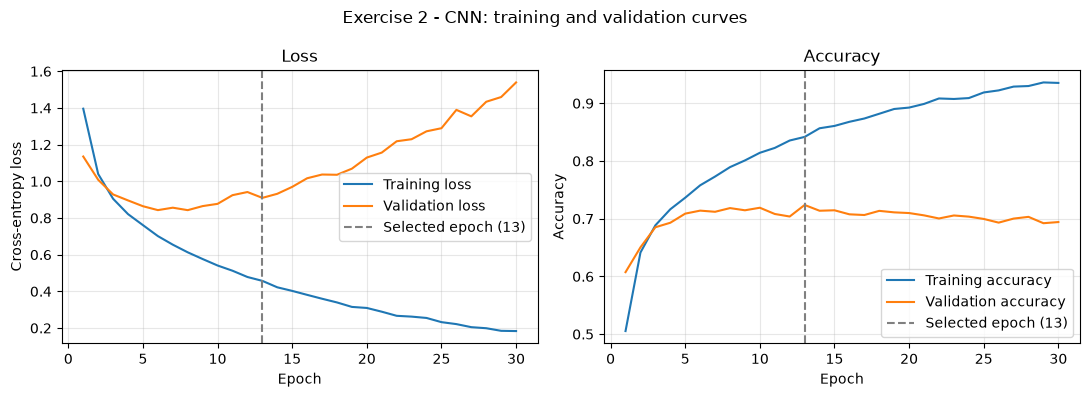

In [7]:
plot_history(history, best_epoch, "Exercise 2 - CNN: training and validation curves", "ex2_cnn_curves.png")

## 7. Final evaluation

The selected model is evaluated once on the clean training images, the validation set and the test set. The confusion matrix shows which classes the CNN mixes up.

Partition       Loss   Accuracy
train         0.3838     87.19%
val           0.9098     72.38%
test          0.9435     71.29%
Generalisation gap (train - test accuracy): 15.90 percentage points


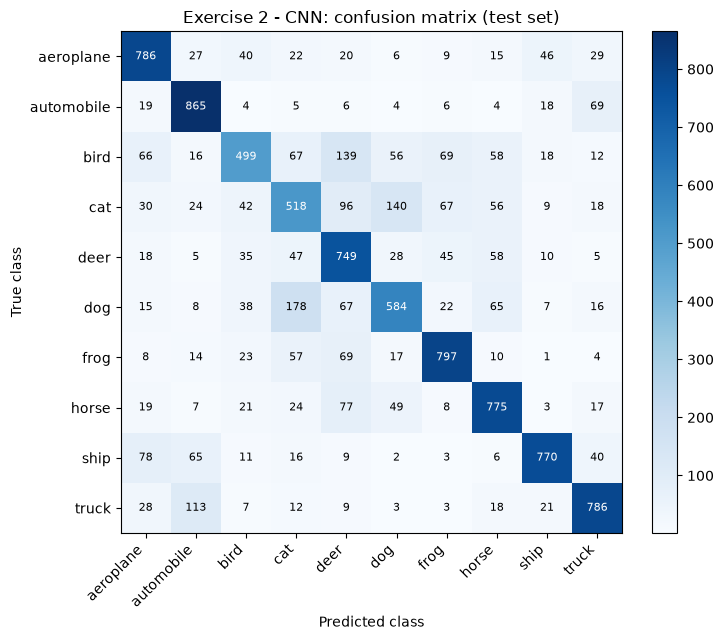


Per-class test accuracy:
  automobile  86.50%
  frog        79.70%
  aeroplane   78.60%
  truck       78.60%
  horse       77.50%
  ship        77.00%
  deer        74.90%
  dog         58.40%
  cat         51.80%
  bird        49.90%


In [8]:
final = final_evaluation(model, loaders)
print_final(final)

cm = plot_confusion_matrix(model, loaders["test"], "Exercise 2 - CNN: confusion matrix (test set)", "ex2_cnn_confusion.png")
per_class = cm.diagonal() / cm.sum(axis=1)
print("\nPer-class test accuracy:")
for name, acc in sorted(zip(CLASSES, per_class), key=lambda t: -t[1]):
    print(f"  {name:<11}{acc * 100:6.2f}%")

## 8. Comparison with Exercise 1 (MLP)

The CNN is compared with the Exercise 1 MLP baseline using exactly the same configuration (seed, split, batch size, optimiser, learning rate and epoch budget), so any difference in the numbers below comes from the architecture rather than the training setup. The comparison is read from `results/ex1_mlp.json`, produced by running `Ex1_MLP.ipynb`.

Metric                         MLP         CNN
Train accuracy              90.51%      87.19%
Val accuracy                53.84%      72.38%
Test accuracy               53.25%      71.29%
Final train loss            0.2772      0.3838
Final val loss              3.0328      0.9098
Selected epoch                  26          13
Parameters               3,676,682      60,362
Training time (s)             17.2        26.6


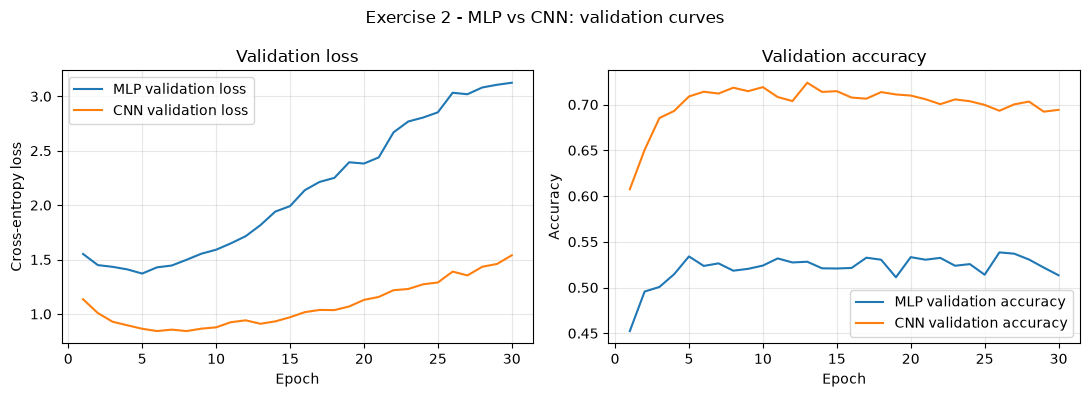

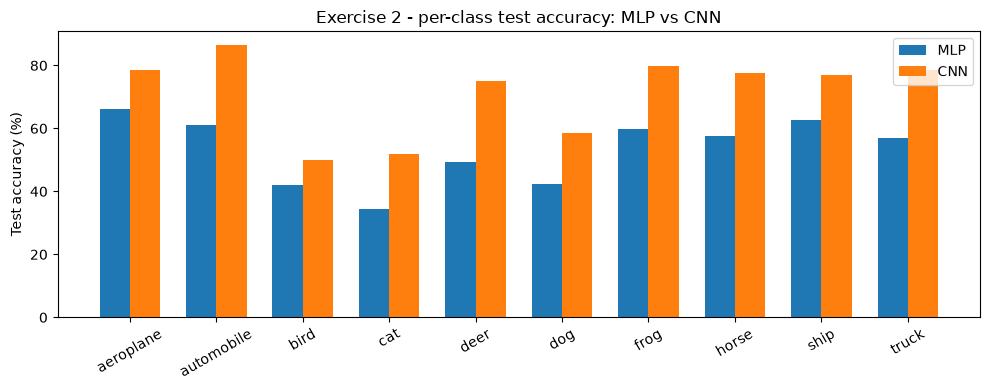

In [9]:
ex1_path = os.path.join(RESULTS_DIR, "ex1_mlp.json")
comparison = None

if not os.path.exists(ex1_path):
    raise FileNotFoundError(f"{ex1_path} not found. Run Ex1_MLP.ipynb first")
else:
    with open(ex1_path) as f:
        mlp = json.load(f)

    comparison = {
        "mlp": {
            "train_acc": mlp["final"]["train_acc"], "val_acc": mlp["final"]["val_acc"],
            "test_acc": mlp["final"]["test_acc"], "train_loss": mlp["final"]["train_loss"],
            "val_loss": mlp["final"]["val_loss"], "best_epoch": mlp["best_epoch"],
            "trainable_parameters": mlp["trainable_parameters"], "train_seconds": mlp["train_seconds"],
        },
        "cnn": {
            "train_acc": final["train_acc"], "val_acc": final["val_acc"],
            "test_acc": final["test_acc"], "train_loss": final["train_loss"],
            "val_loss": final["val_loss"], "best_epoch": best_epoch,
            "trainable_parameters": n_params, "train_seconds": round(train_seconds, 1),
        },
    }

    print(f"{'Metric':<22}{'MLP':>12}{'CNN':>12}")
    rows = [
        ("Train accuracy",    f"{comparison['mlp']['train_acc'] * 100:.2f}%", f"{comparison['cnn']['train_acc'] * 100:.2f}%"),
        ("Val accuracy",      f"{comparison['mlp']['val_acc'] * 100:.2f}%",   f"{comparison['cnn']['val_acc'] * 100:.2f}%"),
        ("Test accuracy",     f"{comparison['mlp']['test_acc'] * 100:.2f}%",  f"{comparison['cnn']['test_acc'] * 100:.2f}%"),
        ("Final train loss",  f"{comparison['mlp']['train_loss']:.4f}",      f"{comparison['cnn']['train_loss']:.4f}"),
        ("Final val loss",    f"{comparison['mlp']['val_loss']:.4f}",        f"{comparison['cnn']['val_loss']:.4f}"),
        ("Selected epoch",    str(comparison['mlp']['best_epoch']),          str(comparison['cnn']['best_epoch'])),
        ("Parameters",        f"{comparison['mlp']['trainable_parameters']:,}", f"{comparison['cnn']['trainable_parameters']:,}"),
        ("Training time (s)", f"{comparison['mlp']['train_seconds']:.1f}",   f"{comparison['cnn']['train_seconds']:.1f}"),
    ]
    for name, mv, cv in rows:
        print(f"{name:<22}{mv:>12}{cv:>12}")

    # Overlaid validation loss / accuracy curves
    mlp_epochs = range(1, len(mlp["history"]["val_loss"]) + 1)
    cnn_epochs = range(1, len(history["val_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(mlp_epochs, mlp["history"]["val_loss"], label="MLP validation loss")
    axes[0].plot(cnn_epochs, history["val_loss"], label="CNN validation loss")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Validation loss")
    axes[1].plot(mlp_epochs, mlp["history"]["val_acc"], label="MLP validation accuracy")
    axes[1].plot(cnn_epochs, history["val_acc"], label="CNN validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Validation accuracy")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle("Exercise 2 - MLP vs CNN: validation curves")
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "ex2_mlp_vs_cnn_curves.png"), dpi=200)
    plt.show()

    # Per-class test accuracy comparison
    mlp_cm = np.array(mlp["confusion_matrix_test"])
    mlp_per_class = mlp_cm.diagonal() / mlp_cm.sum(axis=1)
    x, w = np.arange(len(CLASSES)), 0.35
    plt.figure(figsize=(10, 4))
    plt.bar(x - w / 2, mlp_per_class * 100, w, label="MLP")
    plt.bar(x + w / 2, per_class * 100, w, label="CNN")
    plt.xticks(x, CLASSES, rotation=30)
    plt.ylabel("Test accuracy (%)")
    plt.title("Exercise 2 - per-class test accuracy: MLP vs CNN")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "ex2_per_class_comparison.png"), dpi=200)
    plt.show()

## 9. Visualising what the convolutions learn

Convolutional filters have a small **local receptive field** and the same weights are **shared** across every spatial position, which gives the network **translation equivariance**: shifting the input shifts the output feature map by the same amount, rather than the network having to relearn the same pattern separately at every position, as a fully connected layer would. Stacking convolutional blocks builds a **hierarchy of features**: the first layer tends to respond to edges, colour contrasts and simple textures, and the second layer combines those into larger, more complex patterns built from the first layer's outputs. **Max-pooling** between blocks keeps only the strongest response in each small region, discarding exact position while keeping what was detected, and shrinks the feature maps so that a fixed-size kernel in a later layer effectively covers a larger area of the original image.

Weight sharing is also why the CNN needs far fewer parameters than the MLP for the same input: the first convolution below has only `3 x 3 x 3 x 32 + 32 = 896` parameters because the same 3x3x3 filter slides over every pixel, whereas the MLP's first layer needs one weight per pixel per hidden unit (`3,072 x 1,024 = 3,145,728` weights) because it has no notion of spatial locality or weight sharing at all.

MLP MACs per image = 3072·1024 + 1024·512 + 512·10 = 3,675,136 (about 3.7 M); the CNN figure (5,644,288, about 5.6 M) is counted with forward hooks in Exercise 4.

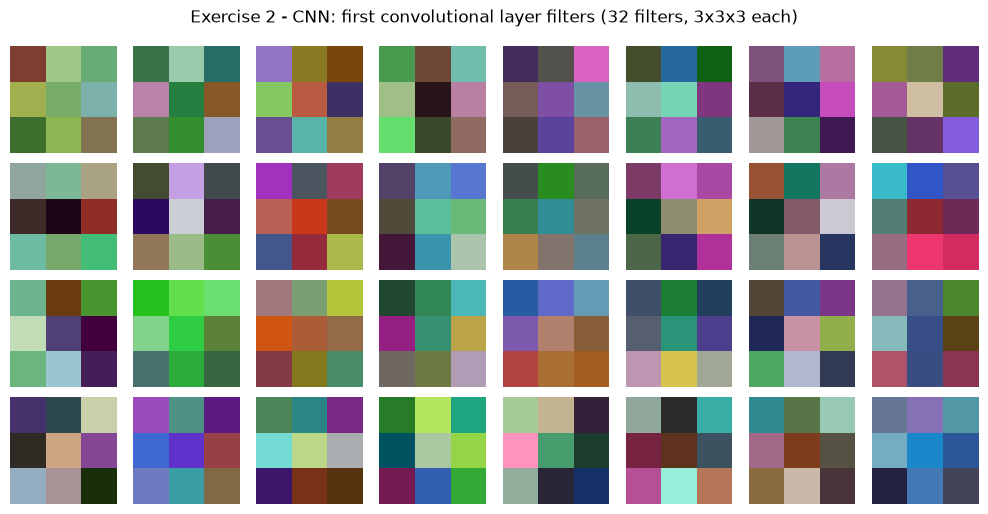

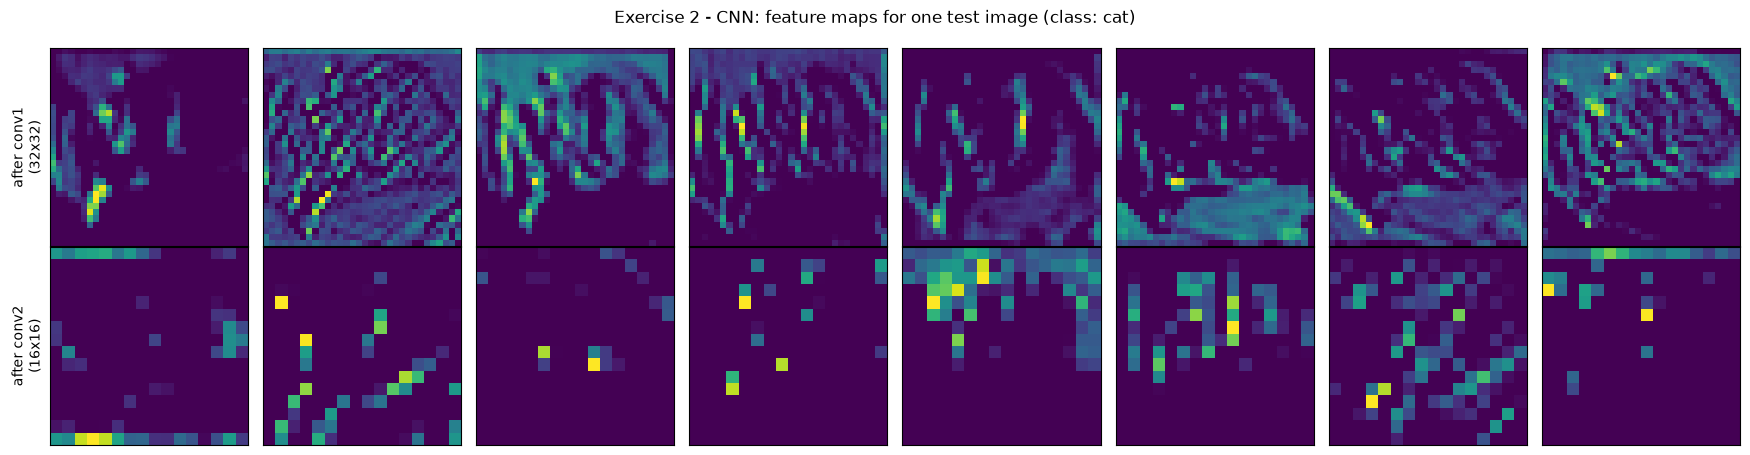

In [10]:
conv1, relu1, pool1, conv2, relu2 = model.net[0], model.net[1], model.net[2], model.net[3], model.net[4]

# First convolutional layer filters (32 filters, each 3x3x3 -- normalised to [0, 1] for display)
filters = conv1.weight.detach().cpu()
filters = (filters - filters.min()) / (filters.max() - filters.min())

fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(filters[i].permute(1, 2, 0))
    ax.axis("off")
fig.suptitle("Exercise 2 - CNN: first convolutional layer filters (32 filters, 3x3x3 each)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex2_cnn_filters.png"), dpi=200)
plt.show()

# Feature maps of one test image after conv1 and after conv2
sample_x, sample_y = loaders["test"].images[:1], loaders["test"].targets[:1]
with torch.no_grad():
    x = (sample_x.float() / 255 - MEAN_T) / STD_T
    feat1 = relu1(conv1(x))             # (1, 32, 32, 32) -- before the first max-pool
    feat2 = relu2(conv2(pool1(feat1)))  # (1, 64, 16, 16) -- before the second max-pool

n_maps = 8
fig, axes = plt.subplots(2, n_maps, figsize=(2.2 * n_maps, 4.6))
for i in range(n_maps):
    axes[0, i].imshow(feat1[0, i].cpu(), cmap="viridis")
    axes[0, i].set_xticks([]); axes[0, i].set_yticks([])
    axes[1, i].imshow(feat2[0, i].cpu(), cmap="viridis")
    axes[1, i].set_xticks([]); axes[1, i].set_yticks([])
axes[0, 0].set_ylabel("after conv1\n(32x32)")
axes[1, 0].set_ylabel("after conv2\n(16x16)")
fig.suptitle(f"Exercise 2 - CNN: feature maps for one test image (class: {CLASSES[sample_y.item()]})")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex2_cnn_featuremaps.png"), dpi=200)
plt.show()

## 10. Save results

The numbers are stored in `results/ex2_cnn.json`, including the comparison against the Exercise 1 MLP, so that the report uses exactly the values produced here.

In [11]:
save_results("ex2_cnn", {
    "experiment": "Exercise 2 - CNN",
    "model": "CNN Conv(3->32)-Conv(32->64)-Linear(4096->10) (ReLU, MaxPool)",
    "trainable_parameters": n_params,
    "best_epoch": best_epoch,
    "train_seconds": round(train_seconds, 1),
    "device": str(DEVICE),
    "config": {"seed": SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
               "learning_rate": LEARNING_RATE, "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "final": final,
    "history": history,
    "confusion_matrix_test": cm.tolist(),
    "comparison": comparison,
})

Saved results\ex2_cnn.json
